In [1]:
import numpy as np
import pandas as pd

In [2]:
# load the dataset
df = pd.read_csv('Market.csv')

In [3]:
df

,Index,Date,Open,High,Low,Close,Adj Close,Volume
0,NYA,12/31/1965,528.690002,528.690002,528.690002,528.690002,528.690002,0.0
1,NYA,01-03-1966,527.210022,527.210022,527.210022,527.210022,527.210022,0.0
2,NYA,01-04-1966,527.840027,527.840027,527.840027,527.840027,527.840027,0.0
3,NYA,01-05-1966,531.119995,531.119995,531.119995,531.119995,531.119995,0.0
4,NYA,01-06-1966,532.070007,532.070007,532.070007,532.070007,532.070007,0.0
...,...,...,...,...,...,...,...,...
1194,N225,11-04-1970,485.549988,485.549988,485.549988,485.549988,485.549988,0.0
1195,N225,11-05-1970,484.380005,484.380005,484.380005,484.380005,484.380005,0.0
1196,N225,11-06-1970,484.809998,484.809998,484.809998,484.809998,484.809998,0.0
1197,N225,11-09-1970,487.339996,487.339996,487.339996,487.339996,487.339996,0.0


In [4]:
# Preview the first few rows
df.head()

,Index,Date,Open,High,Low,Close,Adj Close,Volume
0,NYA,12/31/1965,528.690002,528.690002,528.690002,528.690002,528.690002,0.0
1,NYA,01-03-1966,527.210022,527.210022,527.210022,527.210022,527.210022,0.0
2,NYA,01-04-1966,527.840027,527.840027,527.840027,527.840027,527.840027,0.0
3,NYA,01-05-1966,531.119995,531.119995,531.119995,531.119995,531.119995,0.0
4,NYA,01-06-1966,532.070007,532.070007,532.070007,532.070007,532.070007,0.0


In [5]:

df.tail()

,Index,Date,Open,High,Low,Close,Adj Close,Volume
1194,N225,11-04-1970,485.549988,485.549988,485.549988,485.549988,485.549988,0.0
1195,N225,11-05-1970,484.380005,484.380005,484.380005,484.380005,484.380005,0.0
1196,N225,11-06-1970,484.809998,484.809998,484.809998,484.809998,484.809998,0.0
1197,N225,11-09-1970,487.339996,487.339996,487.339996,487.339996,487.339996,0.0
1198,N225,11-10-1970,488.079987,488.079987,488.079987,488.079987,488.079987,0.0


In [6]:
# Check missing values
df['Low'].isna().sum()

np.int64(3)

In [7]:
df.isna().sum()

Index         0
Date          0
Open          1
High          2
Low           3
Close         4
Adj Close    10
Volume        1
dtype: int64

In [8]:
# handel missing values
df['Low']= df['Low'].fillna(df['Low'].mean())
df['High']= df['High'].fillna(df['High'].mean())
df['Open']= df['Open'].fillna(df['Open'].mean())
df['Close']= df['Close'].fillna(df['Close'].mean())
df['Adj Close']= df['Adj Close'].fillna(df['Adj Close'].mean())
df['Volume']= df['Volume'].fillna(df['Volume'].mean())

# convert 'Date' column to datetime
df['Date'] = pd.to_datetime(
    df['Date'].astype(str).str.replace('-', '/', regex=False),
    format='mixed',
    dayfirst=False,
    errors='coerce'
)
# Extactract Month and Year
df['Month']= df['Date'].dt.month
df['Year'] = df['Date'].dt.year

# remove duplicates
df.drop_duplicates(inplace=True)


In [9]:
df

,Index,Date,Open,High,Low,Close,Adj Close,Volume,Month,Year
0,NYA,1965-12-31,528.690002,528.690002,528.690002,528.690002,528.690002,0.0,12,1965
1,NYA,1966-01-03,527.210022,527.210022,527.210022,527.210022,527.210022,0.0,1,1966
2,NYA,1966-01-04,527.840027,527.840027,527.840027,527.840027,527.840027,0.0,1,1966
3,NYA,1966-01-05,531.119995,531.119995,531.119995,531.119995,531.119995,0.0,1,1966
4,NYA,1966-01-06,532.070007,532.070007,532.070007,532.070007,532.070007,0.0,1,1966
...,...,...,...,...,...,...,...,...,...,...
1194,N225,1970-11-04,485.549988,485.549988,485.549988,485.549988,485.549988,0.0,11,1970
1195,N225,1970-11-05,484.380005,484.380005,484.380005,484.380005,484.380005,0.0,11,1970
1196,N225,1970-11-06,484.809998,484.809998,484.809998,484.809998,484.809998,0.0,11,1970
1197,N225,1970-11-09,487.339996,487.339996,487.339996,487.339996,487.339996,0.0,11,1970


In [10]:
df.isna().sum()

Index        0
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
Month        0
Year         0
dtype: int64

In [11]:
# Summary statistics for numerical columns
summary_status = df[['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']].describe()
summary_status

,Open,High,Low,Close,Adj Close,Volume
count,1199.000000,1199.000000,1199.000000,1199.000000,1199.000000,1199.0
mean,537.620818,542.570626,533.413110,533.422904,537.885138,0.0
std,159.066226,233.205666,53.295643,53.269407,169.612420,0.0
min,398.519989,398.519989,398.519989,398.519989,398.519989,0.0
25%,496.335006,496.490005,496.490005,496.645005,496.645005,0.0
50%,537.250000,537.250000,536.929993,536.929993,537.359985,0.0
75%,570.029999,570.029999,570.029999,570.029999,569.919983,0.0
max,5722.359985,6124.219971,647.849976,647.849976,6110.900024,0.0


In [12]:
# correlation matrix
correlation_matrix = df[['Open', 'High', 'Low', 'Close', 'Adj Close']].corr()
correlation_matrix

,Open,High,Low,Close,Adj Close
Open,1.000000,0.098760,0.354803,0.354642,0.123634
High,0.098760,1.000000,0.283945,0.283852,0.096948
Low,0.354803,0.283945,1.000000,0.997567,0.351949
Close,0.354642,0.283852,0.997567,1.000000,0.351808
Adj Close,0.123634,0.096948,0.351949,0.351808,1.000000


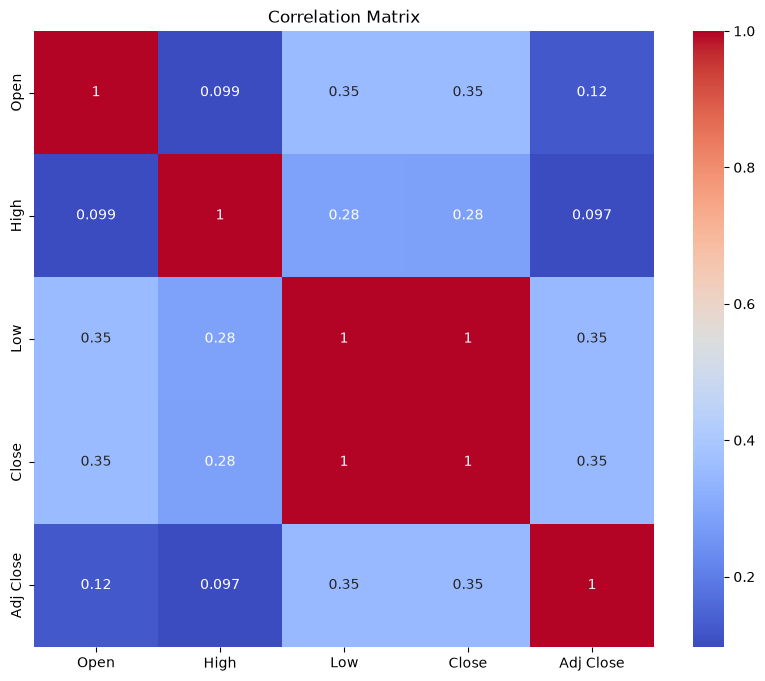

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

# Heatmap of correlation matrix
plt.figure(figsize=(10,8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [14]:
#Top 5 index by volume

top_index = df.groupby('Index')['Close'].sum().nlargest(5)

top_index

Index
DJI     139979.079842
GSPC    138949.560183
IXIC    127458.825578
NYA     117456.935796
N225    115729.659913
Name: Close, dtype: float64

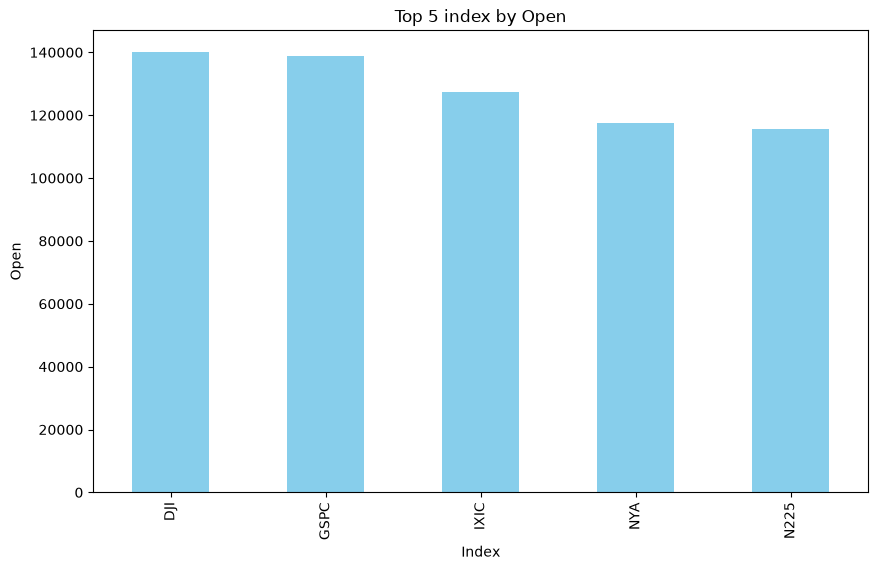

In [15]:
# Plot the bar chart 
top_index.plot(kind='bar',figsize=(10,6), color='skyblue')
plt.title('Top 5 index by Open')
plt.xlabel('Index')
plt.ylabel('Open')
plt.show()

In [16]:
# Monthly High trend
monthly_sales =df.groupby('Month')['High'].sum()

monthly_sales

Month
1     58515.009951
2     50645.230325
3     56890.169830
4     55925.320039
5     62778.919922
6     60100.800205
7     52103.420258
8     54822.260131
9     52538.600628
10    56341.549958
11    45015.829835
12    44865.069820
Name: High, dtype: float64

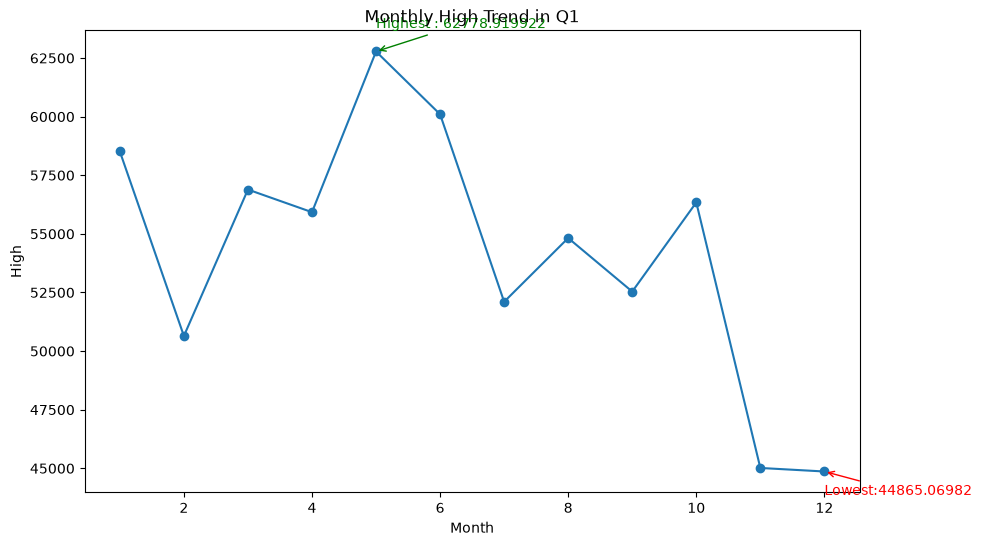

In [17]:
# plot the line chart

plt.figure(figsize=(10, 6))
monthly_sales.plot(kind='line', marker='o')
plt.title('Monthly High Trend in Q1')
plt.xlabel('Month')
plt.ylabel('High')

#Annotate highest and lowest months
max_month = monthly_sales.idxmax()
min_month = monthly_sales.idxmin()

plt.annotate(
            f'Highest : {monthly_sales[max_month]}',
            xy=(max_month, monthly_sales[max_month]),
            xytext=(max_month, monthly_sales[max_month] + 1000),
            arrowprops=dict(arrowstyle='->', color='green'),
            #arrowprops={'arrowstyle': '->', 'color':'green'},
            color='green')
plt.annotate(
            f'Lowest:{monthly_sales[min_month]}',
            xy=(min_month, monthly_sales[min_month]),
            xytext=(min_month, monthly_sales[min_month] - 1000),
            arrowprops=dict(arrowstyle='->', color='red'),
            color='red')
plt.show()

In [18]:
# Plot the bar chart
index_low = df.groupby('Index')['Low'].sum()

index_low

Index
DJI     139979.079842
GSPC    138949.560183
IXIC    127469.622861
N225    115729.659913
NYA     117434.396189
Name: Low, dtype: float64

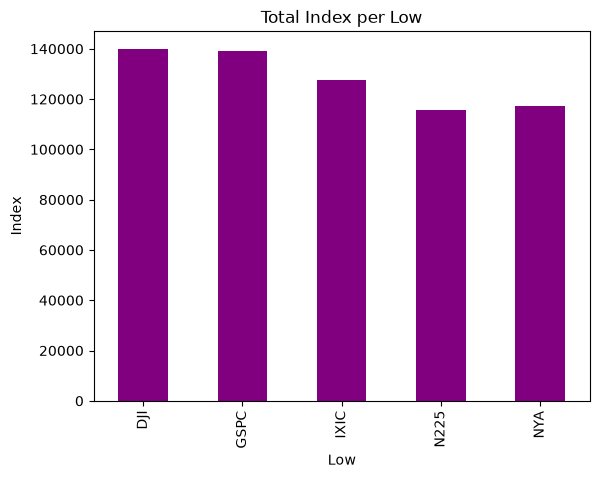

The region with the highest Low is DJI with a Index of 139979.079842.


In [19]:
index_low.plot(kind='bar', color='purple')
plt.title('Total Index per Low')
plt.xlabel('Low')
plt.ylabel('Index')
plt.show()

# identify index with highest Low growth
growth_low = index_low.idxmax()
growth_value = index_low.max()
print(f'The region with the highest Low is {growth_low} with a Index of {growth_value}.')

In [20]:
df

,Index,Date,Open,High,Low,Close,Adj Close,Volume,Month,Year
0,NYA,1965-12-31,528.690002,528.690002,528.690002,528.690002,528.690002,0.0,12,1965
1,NYA,1966-01-03,527.210022,527.210022,527.210022,527.210022,527.210022,0.0,1,1966
2,NYA,1966-01-04,527.840027,527.840027,527.840027,527.840027,527.840027,0.0,1,1966
3,NYA,1966-01-05,531.119995,531.119995,531.119995,531.119995,531.119995,0.0,1,1966
4,NYA,1966-01-06,532.070007,532.070007,532.070007,532.070007,532.070007,0.0,1,1966
...,...,...,...,...,...,...,...,...,...,...
1194,N225,1970-11-04,485.549988,485.549988,485.549988,485.549988,485.549988,0.0,11,1970
1195,N225,1970-11-05,484.380005,484.380005,484.380005,484.380005,484.380005,0.0,11,1970
1196,N225,1970-11-06,484.809998,484.809998,484.809998,484.809998,484.809998,0.0,11,1970
1197,N225,1970-11-09,487.339996,487.339996,487.339996,487.339996,487.339996,0.0,11,1970


In [21]:
index_data = df.groupby('Index').agg({
    'Close' :'count',
    'Adj Close' : 'mean'
    
}).rename(columns={'Close': 'Total Count', 'Adj Close': 'Average Adj Close'})

index_data

,Total Count,Average Adj Close
Index,,
DJI,240,605.922521
GSPC,240,578.351585
IXIC,240,531.593252
N225,239,484.224518
NYA,240,489.110230


In [22]:
# Mannual classification 
def index_classification(row):
    if row['Average Adj Close'] > 100:
        return 'High'
    elif row['Average Adj Close'] > 50:
        return 'Medium'
    else:
        return 'Low value'

# Apply the function to classify index
index_data['Classification'] = index_data.apply(index_classification, axis=1)

# Count the number of index in each classification
index_counts = index_data['Classification'].value_counts()

index_counts

Classification
High    5
Name: count, dtype: int64

In [23]:
index_data

,Total Count,Average Adj Close,Classification
Index,,,
DJI,240,605.922521,High
GSPC,240,578.351585,High
IXIC,240,531.593252,High
N225,239,484.224518,High
NYA,240,489.110230,High


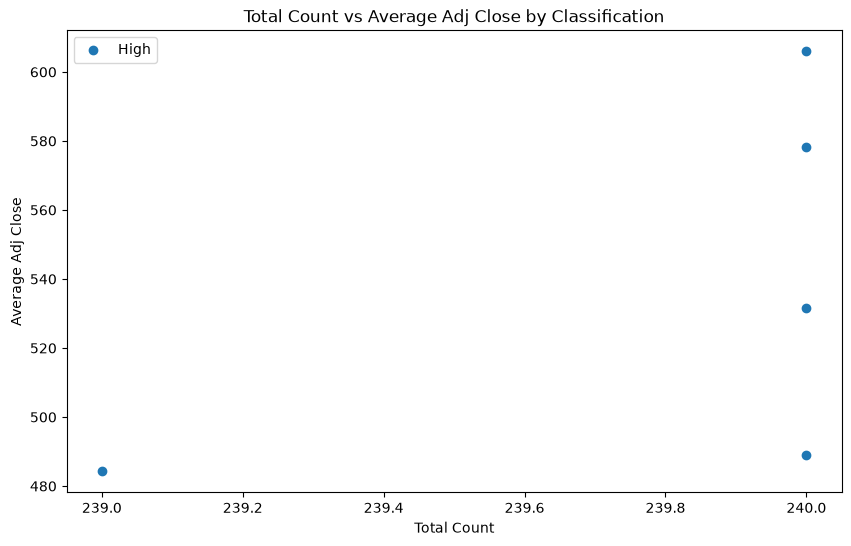

In [24]:
# Scatter plot
plt.figure(figsize=(10, 6))

for label, group in index_data.groupby('Classification'):
    plt.scatter(group['Total Count'], group['Average Adj Close'], label=label)
    
plt.xlabel('Total Count')
plt.ylabel('Average Adj Close')
plt.title('Total Count vs Average Adj Close by Classification')
plt.legend()
plt.show()